# Proyecto 1

In [3]:
import hashlib
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfilt, sosfiltfilt

# Cargando y analizando los datos

Funciones para utilizar después

In [6]:
FS, WIN, STEP = 125, 1000, 250
OVERLAP = WIN - STEP
CH_NAMES = ["ppg1", "ppg2", "accx", "accy", "accz"]


def load_ts(path):
    """Lee un .ts multivariado. Devuelve X (ventanas, canales, muestras) e y (BPM)."""
    X, y, in_data = [], [], False
    with open(path, encoding="utf-8") as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith("#"):
                continue
            if not in_data:
                in_data = line.lower().startswith("@data")
                continue
            *dims, target = line.split(":")
            X.append([[np.nan if v == "?" else float(v) for v in d.split(",")] for d in dims])
            y.append(float(target))
    return np.asarray(X), np.asarray(y)


def _key(a):
    return hashlib.blake2b(np.round(a, 6).tobytes(), digest_size=16).digest()


def reconstruct_recordings(X, y):
    """Une ventanas consecutivas (comparten 750 muestras) en grabaciones continuas."""
    n = len(X)
    starts = {}
    for j in range(n):
        starts.setdefault(_key(X[j, :, :OVERLAP]), []).append(j)
    nxt, has_prev = {}, set()
    for i in range(n):
        cand = [j for j in starts.get(_key(X[i, :, STEP:]), []) if j != i]
        if len(cand) == 1 and cand[0] not in has_prev:
            nxt[i] = cand[0]
            has_prev.add(cand[0])
    recs = []
    for i0 in range(n):
        if i0 in has_prev:
            continue
        chain = [i0]
        while chain[-1] in nxt:
            chain.append(nxt[chain[-1]])
        x = np.concatenate([X[chain[0]]] + [X[j, :, OVERLAP:] for j in chain[1:]], axis=1)
        recs.append({"x": x, "bpm": y[chain], "windows": np.asarray(chain)})
    return recs


def bandpass(x, lo=0.5, hi=4.0, fs=FS, order=4, causal=True):
    """Pasabanda sobre el último eje. causal=True para simular tiempo real."""
    sos = butter(order, [lo, hi], btype="bandpass", fs=fs, output="sos")
    return (sosfilt if causal else sosfiltfilt)(sos, x, axis=-1)


def leave_one_recording_out(n_rec):
    for k in range(n_rec):
        yield [i for i in range(n_rec) if i != k], k


def save_recordings(recs, path):
    data = {}
    for k, r in enumerate(recs):
        data[f"rec{k}_x"], data[f"rec{k}_bpm"], data[f"rec{k}_windows"] = r["x"], r["bpm"], r["windows"]
    np.savez_compressed(path, n_rec=len(recs), **data)


def load_recordings(path):
    z = np.load(path)
    return [{"x": z[f"rec{k}_x"], "bpm": z[f"rec{k}_bpm"], "windows": z[f"rec{k}_windows"]}
            for k in range(int(z["n_rec"]))]

def prepare_recording(rec, primary="mean", lo=0.5, hi=4.0):
    """
    Devuelve:
      d   : señal primaria, (N,)   — PPG filtrada y normalizada
      acc : referencias, (3, N)    — acelerómetro filtrado y normalizado
      bpm : BPM de referencia por ventana, (n_ventanas,)
    """
    x = rec["x"]
    ppg = bandpass(x[:2], lo, hi, causal=True)
    acc = bandpass(x[2:], lo, hi, causal=True)
    d = ppg.mean(axis=0) if primary == "mean" else ppg[int(primary)]
    d = (d - d.mean()) / d.std()
    acc = (acc - acc.mean(axis=1, keepdims=True)) / acc.std(axis=1, keepdims=True)
    return d, acc, rec["bpm"]


def split_windows(sig, win=WIN, step=STEP):
    """Corta una señal (N,) en ventanas de 8 s cada 2 s. Devuelve (n_ventanas, 1000)."""
    n_win = (len(sig) - win) // step + 1
    return np.stack([sig[k * step : k * step + win] for k in range(n_win)])

Cargando y reorganizando los datos

(1768, 5, 1000) (1328, 5, 1000)
12 10


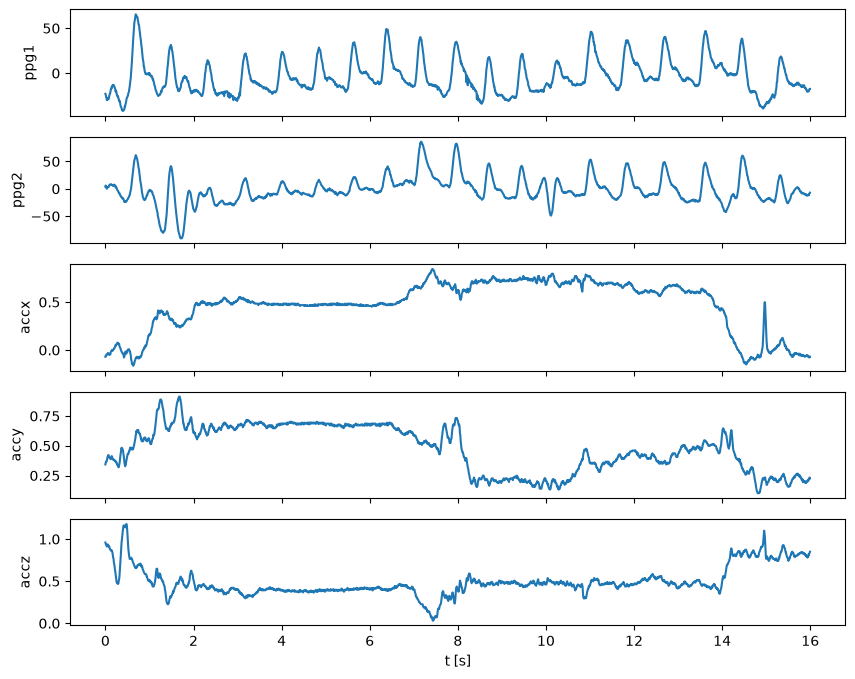

In [5]:
# Archivos en la misma carpeta que el notebook:
PATH_TRAIN = "IEEEPPG_TRAIN.ts"
PATH_TEST = "IEEEPPG_TEST.ts"

X_tr, y_tr = load_ts(PATH_TRAIN)
X_te, y_te = load_ts(PATH_TEST)
print(X_tr.shape, X_te.shape)          # (1768, 5, 1000) y (1328, 5, 1000)

recs_train = reconstruct_recordings(X_tr, y_tr)
recs_test = reconstruct_recordings(X_te, y_te)
print(len(recs_train), len(recs_test))  # 12 y 10

# Opcional: guardar para no repetir el paso lento la próxima vez
save_recordings(recs_train, "recordings_train.npz")
save_recordings(recs_test, "recordings_test.npz")
# y para recargar después:
# recs_train = load_recordings("recordings_train.npz")
# recs_test  = load_recordings("recordings_test.npz")

# Ejemplo de uso: una grabación, PPG filtrada y acelerómetro como referencias
r = recs_train[0]
ppg = bandpass(r["x"][:2])             # (2, N), canales ppg1 y ppg2
acc = bandpass(r["x"][2:])             # (3, N), ejes x, y, z
bpm_ref = r["bpm"]                      # un valor por ventana de 8 s, avanzando de a 2 s

# Gráfico para confirmar el orden de los canales
t = np.arange(r["x"].shape[1]) / FS
fig, axes = plt.subplots(5, 1, figsize=(10, 8), sharex=True)
for c, ax in enumerate(axes):
    ax.plot(t[:2000], r["x"][c, :2000])
    ax.set_ylabel(CH_NAMES[c])
axes[-1].set_xlabel("t [s]")
plt.show()

In [9]:
def build_U(acc, M):
    """Fila n = [ejex(n), ejex(n-1), ..., ejex(n-M+1), ejey(n), ..., ejez(n-M+1)] (ceros antes de n=0)."""
    n_ref, N = acc.shape
    U = np.zeros((N, n_ref * M))
    for k in range(n_ref):
        padded = np.concatenate([np.zeros(M - 1), acc[k]])
        for i in range(M):
            U[:, k * M + i] = padded[M - 1 - i : M - 1 - i + N]
    return U


def lms(d, U, mu):
    """LMS clásico. Devuelve e (señal limpia), y (estimación del artefacto), w (pesos finales)."""
    N, L = U.shape
    w = np.zeros(L)
    e = np.zeros(N)
    y = np.zeros(N)
    for n in range(N):
        y[n] = w @ U[n]            # salida del filtro
        e[n] = d[n] - y[n]         # error = PPG limpia
        w = w + mu * e[n] * U[n]   # actualización
    return e, y, w


# Prueba con la grabación 0
d, acc, bpm = prepare_recording(recs_train[0])
M, mu = 32, 0.005
U = build_U(acc, M)
e, y, w = lms(d, U, mu)
print(U.shape, e.std(), np.isfinite(e).all())

(37750, 96) 0.41280079899651295 True
